# 第 29 课｜第一阶段实战:画一份策略报告

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`29_youtube-e3X6Ozwhz7k/index.html`  
> **所属模块**：P1-M6 · 数据契约与策略报告

## 本节量化问题

如何把交易想法整理成包含基准、风险、成本和边界的可复现报告？

## 准确定义与策略报告位置

策略报告是研究假设、数据契约、信号规则、收益风险、统计证据、执行成本和稳健性结论的同一份证据链。

- **核心关系**：净策略收益=持仓×下一期资产收益-换手×单位成本；所有指标必须与同频基准对齐。
- **写入报告**：完整策略研究报告
- **P2 衔接**：P2 第 40–46、56、59–60 课：可视化、测试、自动报告和审计。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 定义无未来信息的信号和下一日持仓

均线在收盘后形成，因此使用 `signal.shift(1)` 表示最早下一交易日持有。换手在持仓变化时发生。

In [2]:
from src.quant_core import performance_summary

daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
close = daily.pivot(index="date", columns="symbol", values="adj_close").sort_index()
asset = close["SIM_GROWTH"]
benchmark = close["SIM_MARKET"].pct_change(fill_method=None)

fast = asset.rolling(20, min_periods=20).mean()
slow = asset.rolling(60, min_periods=60).mean()
signal = (fast > slow).astype(float)
position = signal.shift(1).fillna(0.0)
asset_return = asset.pct_change(fill_method=None)
turnover = position.diff().abs().fillna(position.abs())
cost_per_turnover = 0.0005
strategy = position * asset_return - turnover * cost_per_turnover

metrics = performance_summary(strategy, benchmark)
display(metrics.to_frame("value"))

,value
strategy_annual_return,0.076962
benchmark_annual_return,-0.012624
strategy_annual_volatility,0.142780
max_drawdown,-0.180157
beta,0.489851
mean_daily_excess,0.000347
observations,755.000000


## 生成包含策略与基准的研究报告

报告记录模拟数据身份、信号时点和成本假设。它是方法演示，不是投资建议或未来收益承诺。

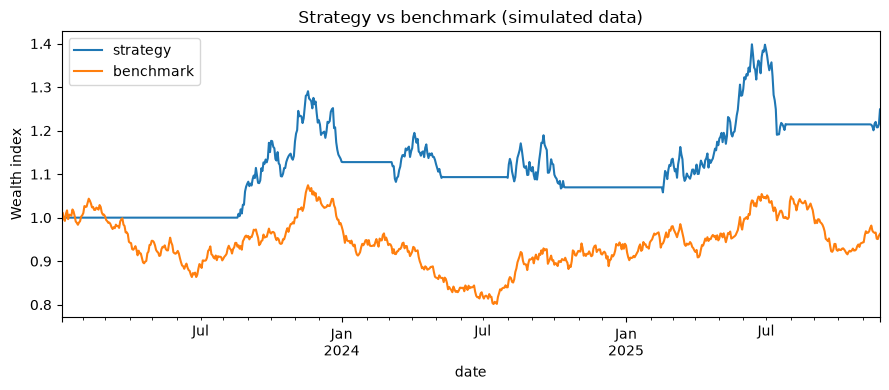

已生成: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/outputs/29_strategy_report.html


In [3]:
aligned = pd.concat([strategy.rename("strategy"), benchmark.rename("benchmark")], axis=1).dropna()
nav = (1.0 + aligned).cumprod()
ax = nav.plot(figsize=(9, 4), title="Strategy vs benchmark (simulated data)")
ax.set_ylabel("Wealth index")
plt.tight_layout()
figure_path = OUTPUT_DIR / "29_strategy_vs_benchmark.png"
plt.savefig(figure_path, dpi=150)
plt.show()

report_rows = "".join(
    f"<tr><th>{key}</th><td>{value:.6f}</td></tr>" if isinstance(value, (float, np.floating))
    else f"<tr><th>{key}</th><td>{value}</td></tr>"
    for key, value in metrics.items()
)
report_html = f"""<!doctype html><meta charset='utf-8'>
<title>P1 strategy research report</title>
<h1>策略研究报告：双均线教学样例</h1>
<p><strong>数据：</strong>固定种子模拟日线，不是真实证券。</p>
<p><strong>假设：</strong>中期趋势持续性可能带来成本后收益；20/60 日均线仅作教学规则。</p>
<p><strong>执行：</strong>收盘形成信号，下一交易日持仓；单边换手成本 5 bps。</p>
<h2>收益、风险与基准</h2><table>{report_rows}</table>
<h2>边界</h2><p>未进行参数搜索、滚动样本外、容量、税费和模拟盘验证，不构成收益承诺。</p>
"""
report_path = OUTPUT_DIR / "29_strategy_report.html"
report_path.write_text(report_html, encoding="utf-8")
print("已生成:", report_path)

## 方法边界与阶段验收

教学报告不是收益承诺，也不等于实盘审批；仍需样本外、模拟盘、限额和故障恢复。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
